# Olist E-commerce — Visual Analysis

This notebook runs the SQL queries in `sql/` against the local DuckDB database and charts the main results.

**Before running:** load the data with `python scripts/load_data.py` (see the README).

Revenue = sum of item prices on delivered orders (excluding freight), in Brazilian reais (R$).

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "sql").exists() else Path.cwd().parent
IMG_DIR = ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)

con = duckdb.connect(str(ROOT / "data" / "olist.duckdb"), read_only=True)


def run_query(name: str) -> pd.DataFrame:
    """Run sql/<name>.sql and return the result as a DataFrame."""
    return con.execute((ROOT / "sql" / f"{name}.sql").read_text(encoding="utf-8")).df()


# One visual style for every chart
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 14,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": AXIS, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
})


def hbar(ax, labels, values, fmt, color=BLUE):
    """Horizontal bar chart, largest on top, with a value label on every bar."""
    bars = ax.barh(labels, values, color=color, height=0.62)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.bar_label(bars, labels=[fmt(v) for v in values], padding=4, color=INK_2, fontsize=9)
    ax.set_xlim(0, max(values) * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)


def vbar(ax, labels, values, fmt, color=BLUE):
    """Vertical bar chart with a value label on every bar."""
    bars = ax.bar(labels, values, color=color, width=0.6)
    ax.grid(axis="x", visible=False)
    ax.bar_label(bars, labels=[fmt(v) for v in values], padding=3, color=INK_2, fontsize=9)
    ax.set_ylim(0, max(values) * 1.14)
    ax.yaxis.set_visible(False)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Revenue grew fast through 2017, then levelled off

Months before January 2017 and after August 2018 are excluded: the dataset only has a handful of orders in them.

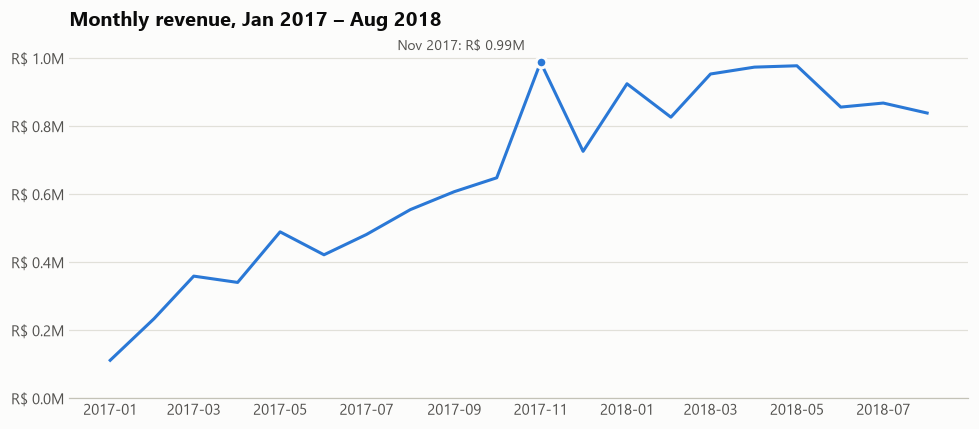

,purchase_month,orders,revenue,avg_order_value
17,2018-03-01,7003,953356.25,136.14
18,2018-04-01,6798,973534.09,143.21
19,2018-05-01,6749,977544.69,144.84
20,2018-06-01,6099,856077.86,140.36
21,2018-07-01,6159,867953.46,140.92
22,2018-08-01,6351,838576.64,132.04


In [2]:
monthly = run_query("01_monthly_revenue")
monthly["purchase_month"] = pd.to_datetime(monthly["purchase_month"])
monthly = monthly[monthly["purchase_month"].between("2017-01-01", "2018-08-01")]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly["purchase_month"], monthly["revenue"] / 1e6, color=BLUE, linewidth=2)
ax.grid(axis="x", visible=False)
ax.set_ylim(0)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("R$ %.1fM"))
ax.set_title("Monthly revenue, Jan 2017 – Aug 2018")

peak = monthly.loc[monthly["revenue"].idxmax()]
ax.plot(peak["purchase_month"], peak["revenue"] / 1e6, "o", color=BLUE, markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.annotate(f"{peak['purchase_month']:%b %Y}: R$ {peak['revenue'] / 1e6:.2f}M",
            (peak["purchase_month"], peak["revenue"] / 1e6),
            xytext=(-10, 8), textcoords="offset points", ha="right", color=INK_2, fontsize=9)
save(fig, "01_monthly_revenue")
plt.show()

monthly[["purchase_month", "orders", "revenue", "avg_order_value"]].tail(6)

## 2. Seven categories make half of the revenue

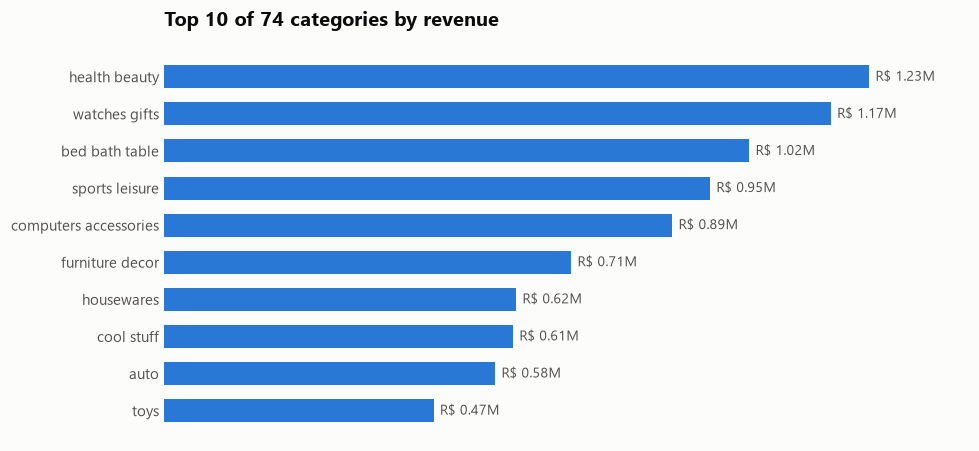

8 categories reach 50% of revenue; the top 10 reach 62%.


In [3]:
categories = run_query("02_category_pareto")
top = categories.head(10)

fig, ax = plt.subplots(figsize=(9, 4.2))
hbar(ax, top["category"].str.replace("_", " "), top["revenue"] / 1e6, lambda v: f"R$ {v:.2f}M")
ax.set_title(f"Top 10 of {len(categories)} categories by revenue")
save(fig, "02_top_categories")
plt.show()

n_half = int((categories["cumulative_share_pct"] < 50).sum()) + 1
print(f"{n_half} categories reach 50% of revenue; the top 10 reach "
      f"{top['cumulative_share_pct'].iloc[-1]:.0f}%.")

## 3. Almost nobody buys twice

This is the most important number in the dataset: growth depends almost entirely on new customers.

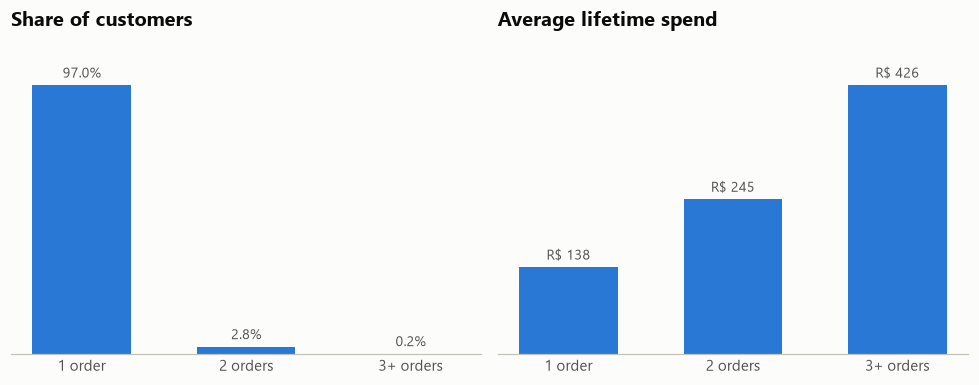

,purchase_frequency,customers,customer_share_pct,revenue,revenue_share_pct,avg_lifetime_value
0,1 order,90557,97.00,12493089.36,94.49,137.96
1,2 orders,2573,2.76,631274.90,4.77,245.35
2,3+ orders,228,0.24,97133.85,0.73,426.03


In [4]:
repeat = run_query("05_repeat_purchase")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
vbar(axes[0], repeat["purchase_frequency"], repeat["customer_share_pct"], lambda v: f"{v:.1f}%")
axes[0].set_title("Share of customers")
vbar(axes[1], repeat["purchase_frequency"], repeat["avg_lifetime_value"], lambda v: f"R$ {v:.0f}")
axes[1].set_title("Average lifetime spend")
save(fig, "03_repeat_purchase")
plt.show()

repeat

## 4. Late delivery destroys review scores

The penalty is small for delays of up to 3 days and severe after that.

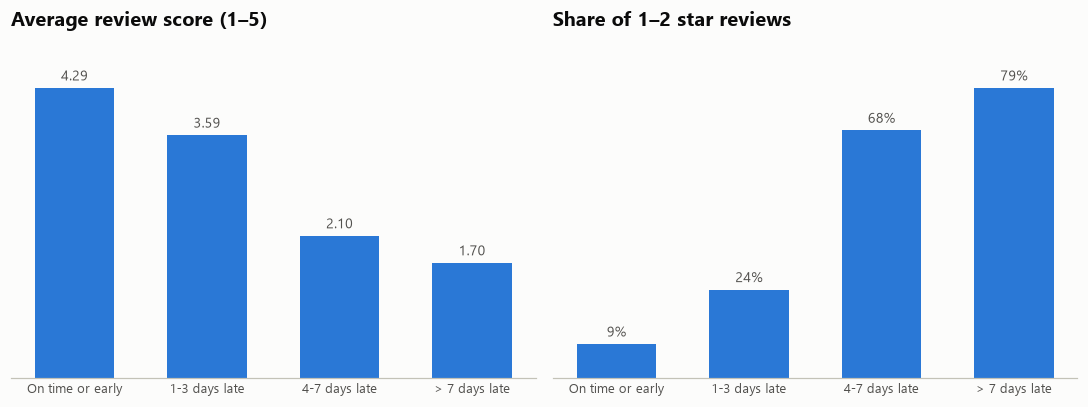

,delivery_bucket,orders,order_share_pct,avg_review_score,bad_review_pct,five_star_pct
0,1. On time or early,88163,92.0,4.29,9.2,62.4
1,2. 1-3 days late,3132,3.3,3.59,24.1,40.3
2,3. 4-7 days late,1748,1.8,2.10,67.7,14.1
3,4. More than 7 days late,2781,2.9,1.70,79.3,7.0


In [5]:
late = run_query("07_late_delivery_vs_reviews")
buckets = late["delivery_bucket"].str.replace(r"^\d\. ", "", regex=True).str.replace("More than", ">")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
vbar(axes[0], buckets, late["avg_review_score"], lambda v: f"{v:.2f}")
axes[0].set_title("Average review score (1–5)")
vbar(axes[1], buckets, late["bad_review_pct"], lambda v: f"{v:.0f}%")
axes[1].set_title("Share of 1–2 star reviews")
for ax in axes:
    ax.tick_params(axis="x", labelsize=8.5)
save(fig, "04_late_delivery_reviews")
plt.show()

late

## 5. Delivery is worst in the Northeast

States with fewer than 50 delivered orders are excluded.

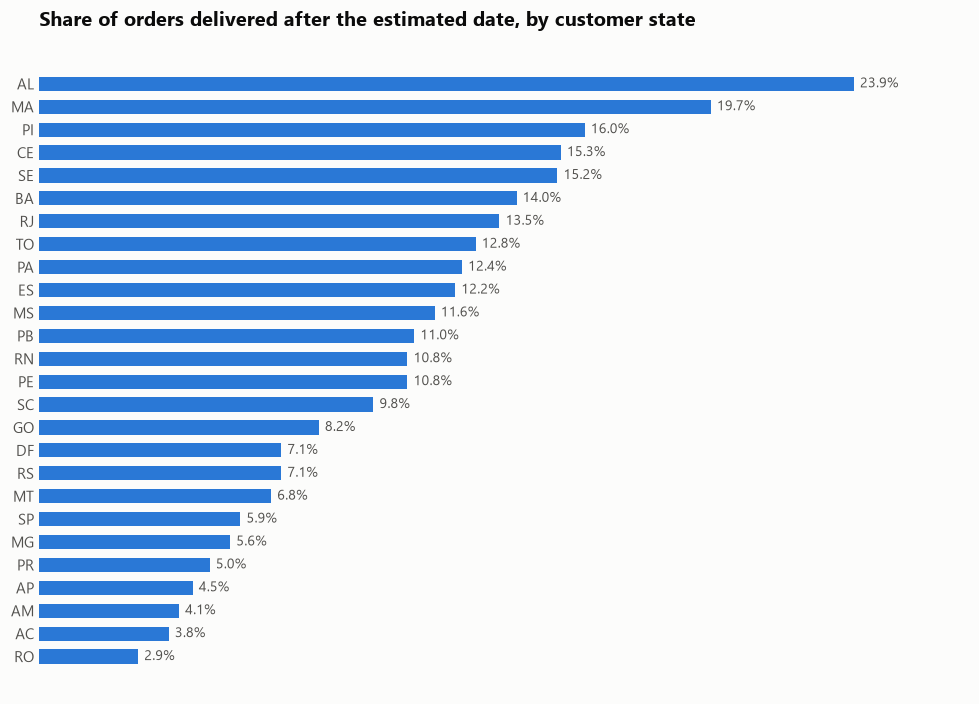

In [6]:
states = run_query("06_delivery_by_state").sort_values("late_pct", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
hbar(ax, states["customer_state"], states["late_pct"], lambda v: f"{v:.1f}%")
ax.set_title("Share of orders delivered after the estimated date, by customer state")
save(fig, "05_late_by_state")
plt.show()

## 6. A small group of sellers carries the marketplace

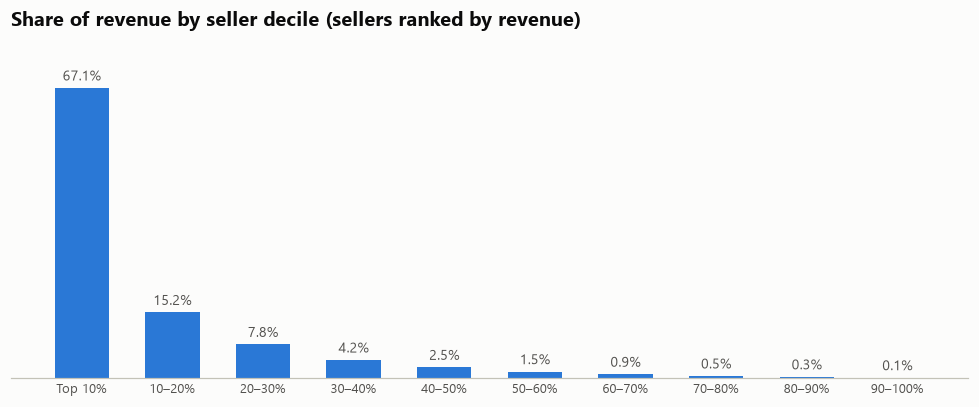

297 sellers generate 67% of revenue.


In [7]:
sellers = run_query("09_seller_concentration")
labels = ["Top 10%"] + [f"{(d - 1) * 10}–{d * 10}%" for d in sellers["revenue_decile"][1:]]

fig, ax = plt.subplots(figsize=(9, 3.8))
vbar(ax, labels, sellers["revenue_share_pct"], lambda v: f"{v:.1f}%")
ax.set_title("Share of revenue by seller decile (sellers ranked by revenue)")
ax.tick_params(axis="x", labelsize=8.5)
save(fig, "06_seller_concentration")
plt.show()

print(f"{int(sellers['sellers'].iloc[0])} sellers generate {sellers['revenue_share_pct'].iloc[0]:.0f}% of revenue.")

## 7. Installments go with bigger baskets

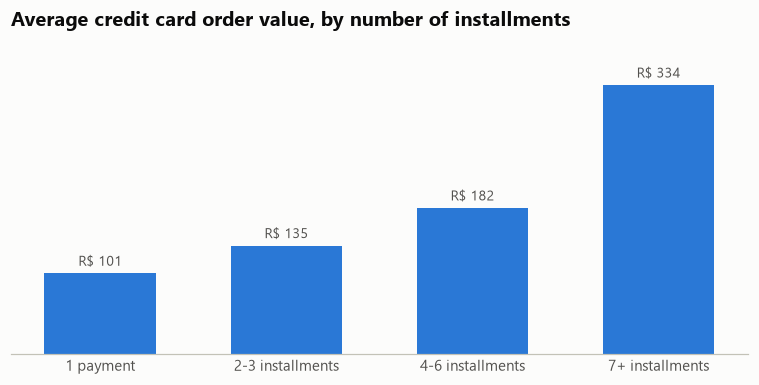

In [8]:
payments = run_query("08_payment_methods")
cards = payments[payments["main_payment_type"] == "credit_card"].sort_values("installments_bucket")
labels = cards["installments_bucket"].str.replace(" (single payment)", "", regex=False) + " installments"
labels = labels.str.replace("^1 installments", "1 payment", regex=True)

fig, ax = plt.subplots(figsize=(7, 3.6))
vbar(ax, labels, cards["avg_order_paid"], lambda v: f"R$ {v:.0f}")
ax.set_title("Average credit card order value, by number of installments")
save(fig, "07_installments")
plt.show()

## 8. Customer segments (RFM)

Two segments of one-time, high-spending customers hold most of the revenue. The "at risk" group has not bought for over a year on average.

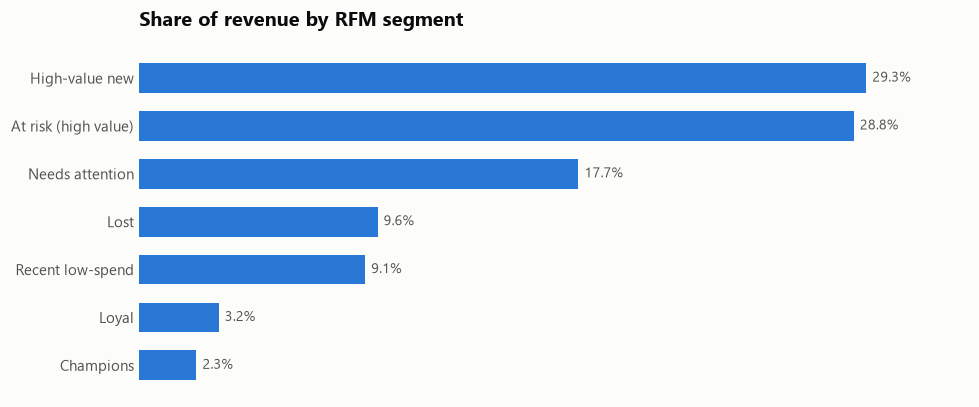

,segment,customers,customer_share_pct,revenue,revenue_share_pct,avg_spend,avg_recency_days,avg_orders
0,High-value new,14532,15.6,3874392.59,29.3,266.61,92.0,1.00
1,At risk (high value),13727,14.7,3810491.93,28.8,277.59,394.0,1.00
2,Needs attention,18069,19.4,2346376.48,17.7,129.86,219.0,1.00
3,Lost,22620,24.2,1264720.12,9.6,55.91,395.0,1.00
4,Recent low-spend,21609,23.1,1197108.24,9.1,55.40,89.0,1.00
5,Loyal,1870,2.0,423286.46,3.2,226.36,285.0,2.08
6,Champions,931,1.0,305122.29,2.3,327.74,88.0,2.19


In [9]:
rfm = run_query("04_rfm_segmentation")

fig, ax = plt.subplots(figsize=(9, 3.8))
hbar(ax, rfm["segment"], rfm["revenue_share_pct"], lambda v: f"{v:.1f}%")
ax.set_title("Share of revenue by RFM segment")
save(fig, "08_rfm_segments")
plt.show()

rfm

## Conclusions

1. **Retention is the main opportunity.** 97% of customers buy once. Repeat customers are worth roughly twice as much or more.
2. **Delays over 3 days are the main driver of bad reviews**, and they are concentrated in Northeast states.
3. **Revenue depends on a small group of sellers and categories**, which is both a risk and a clear place to focus account management.

These are correlations in historical data. Each recommendation in the README should be validated with an experiment before a full rollout.

In [10]:
con.close()